# Data Preprocessing: Market Basket Optimisation (Kaggle Benchmark)
Notebook ini memuat tahap pra-pemrosesan data (*Data Understanding & Preprocessing*) untuk dataset keranjang belanja ritel internasional (*Market Basket Optimisation*).

* **Dataset Asal:** `Market_Basket_Optimisation.csv` (7.501 transaksi ritel supermarket)
* **Karakteristik Data:** 7.501 transaksi keranjang belanja dengan 20 slot produk horizontal (`item1` s.d `item20`) dan 119 varian produk unik.
* **Fokus Analisis:**
  1. Pemeriksaan Dimensi Data (Jumlah Record & Atribut)
  2. Analisis Nilai Kosong (*Missing Value*) & Visualisasi Heatmap
  3. Pemeriksaan Data Duplikat & Transaksi Unik
  4. Analisis Frekuensi Produk Terpopuler
  5. Deteksi Data Pencilan (*Outlier*) pada Ukuran Keranjang Belanja menggunakan Metode IQR dan Boxplot


### 1. Import Library
Memanggil library data science (pandas, numpy, matplotlib, seaborn).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### 2. Membaca Dataset
Memuat file CSV dataset transaksi keranjang belanja ke dalam DataFrame pandas.


In [2]:
df = pd.read_csv('market_basket_optimisation.csv')


### 3. Menampilkan 5 Data Teratas (Head)
Melihat sampel 5 baris pertama data transaksi belanja.


In [3]:
df.head()


,transaction_id,item1,item2,item3,item4,item5,item6,item7,item8,item9,...,item11,item12,item13,item14,item15,item16,item17,item18,item19,item20
0,1,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,...,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,2,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 4. Menampilkan 5 Data Terbawah (Tail)
Melihat sampel 5 baris terakhir data transaksi belanja.


In [4]:
df.tail()


,transaction_id,item1,item2,item3,item4,item5,item6,item7,item8,item9,...,item11,item12,item13,item14,item15,item16,item17,item18,item19,item20
7496,7497,butter,light mayo,fresh bread,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7497,7498,burgers,frozen vegetables,eggs,french fries,magazines,green tea,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7498,7499,chicken,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7499,7500,escalope,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7500,7501,eggs,frozen smoothie,yogurt cake,low fat yogurt,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 5. Jumlah Baris (Record)
Menghitung total baris transaksi pada dataset.


In [5]:
print("Jumlah Baris:", len(df))


Jumlah Baris: 7501


### 6. Jumlah Kolom (Atribut)
Menghitung total kolom pada dataset.


In [6]:
print("Jumlah Kolom:", len(df.columns))


Jumlah Kolom: 21


### 7. Cek Tipe Data & Struktur DataFrame
Memeriksa informasi tipe data setiap kolom dan ringkasan penggunaan memori.


In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7501 entries, 0 to 7500
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   transaction_id  7501 non-null   int64
 1   item1           7501 non-null   str  
 2   item2           5747 non-null   str  
 3   item3           4389 non-null   str  
 4   item4           3345 non-null   str  
 5   item5           2529 non-null   str  
 6   item6           1864 non-null   str  
 7   item7           1369 non-null   str  
 8   item8           981 non-null    str  
 9   item9           654 non-null    str  
 10  item10          395 non-null    str  
 11  item11          256 non-null    str  
 12  item12          154 non-null    str  
 13  item13          87 non-null     str  
 14  item14          47 non-null     str  
 15  item15          25 non-null     str  
 16  item16          8 non-null      str  
 17  item17          4 non-null      str  
 18  item18          4 non-null      str  
 

### 8. Cek Missing Value per Kolom
Menghitung jumlah nilai kosong (NaN/null) pada masing-masing kolom produk horizontal.


In [8]:
df.isnull().sum().to_frame(name='Jumlah Missing Value')


,Jumlah Missing Value
transaction_id,0
item1,0
item2,1754
item3,3112
item4,4156
item5,4972
item6,5637
item7,6132
item8,6520
item9,6847


### 9. Total Missing Value Keseluruhan
Menghitung total seluruh nilai kosong pada dataset.


In [9]:
print("Total Missing Value Keseluruhan:", df.isnull().sum().sum())


Total Missing Value Keseluruhan: 120657


### 10. Persentase Missing Value
Menghitung rasio persentase data kosong terhadap total sel data.


In [10]:
total_sel = len(df) * len(df.columns)
persen_missing = (df.isnull().sum().sum() / total_sel) * 100
print(f"Persentase Missing Value: {persen_missing:.2f}%")


Persentase Missing Value: 76.60%


### 11. Visualisasi Heatmap Missing Value
Menampilkan peta sebaran nilai kosong pada seluruh transaksi belanja.


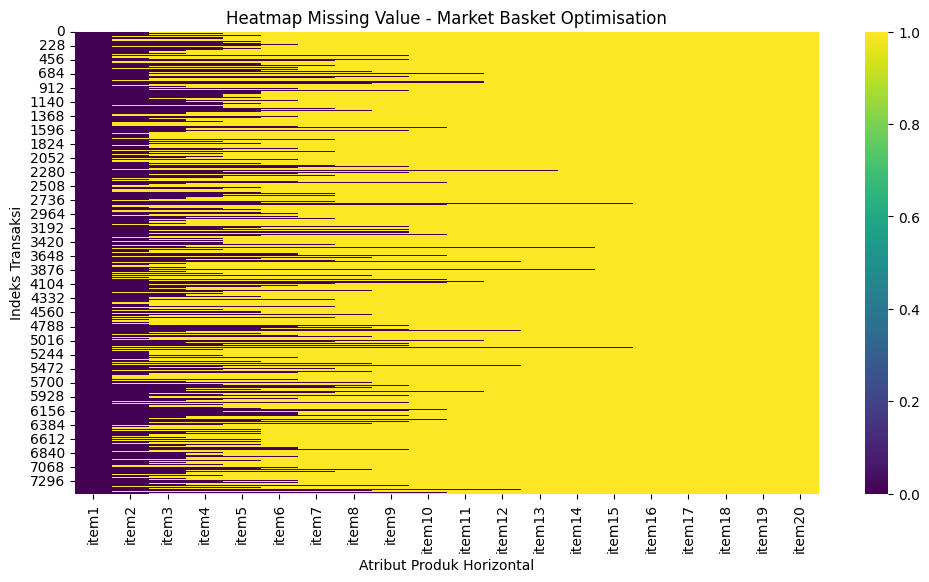

In [11]:
plt.figure(figsize=(12, 6))
sns.heatmap(df.drop(columns=['transaction_id']).isnull(), cbar=True, cmap='viridis')
plt.title('Heatmap Missing Value - Market Basket Optimisation')
plt.xlabel('Atribut Produk Horizontal')
plt.ylabel('Indeks Transaksi')
plt.show()


### 12. Cek Jumlah Duplikat Transaksi
Memeriksa baris belanja dengan kombinasi item yang identik.


In [12]:
item_cols = [c for c in df.columns if c != 'transaction_id']
jumlah_duplikat = df.drop(columns=['transaction_id']).duplicated().sum()
print("Jumlah Transaksi Duplikat:", jumlah_duplikat)


Jumlah Transaksi Duplikat: 2325


### 13. Cek Jumlah Transaksi Unik
Menghitung total identifier transaksi unik (transaction_id).


In [13]:
print("Jumlah Transaksi Unik:", df['transaction_id'].nunique())


Jumlah Transaksi Unik: 7501


### 14. Frekuensi Produk Terpopuler
Menghitung frekuensi kemunculan 10 produk teratas di seluruh keranjang belanja.


In [14]:
item_cols = [c for c in df.columns if c != 'transaction_id']
all_items = pd.Series(df[item_cols].values.flatten()).dropna().str.strip()
all_items = all_items[all_items != '']
top_items = all_items.value_counts().to_frame(name='Jumlah Pembelian')
print("Frekuensi 10 Produk Terpopuler:")
display(top_items.head(10))


Frekuensi 10 Produk Terpopuler:


,Jumlah Pembelian
mineral water,1788
eggs,1348
spaghetti,1306
french fries,1282
chocolate,1230
green tea,991
milk,972
ground beef,737
frozen vegetables,715
pancakes,713


### 15. Hitung Ukuran Keranjang Belanja per Transaksi
Menghitung banyaknya produk yang dibeli pada setiap nomor transaksi.


In [15]:
item_cols = [c for c in df.columns if c != 'transaction_id']
item_per_transaksi = df[item_cols].notna().sum(axis=1)
item_per_transaksi.name = 'Ukuran_Keranjang' 


### 16. Statistik Deskriptif Ukuran Keranjang Belanja
Melihat nilai rata-rata, standar deviasi, nilai minimum, dan maksimum ukuran keranjang belanja.


In [16]:
item_per_transaksi.describe().to_frame(name='Statistik Deskriptif')


,Statistik Deskriptif
count,7501.000000
mean,3.914545
std,2.905540
min,1.000000
25%,2.000000
50%,3.000000
75%,5.000000
max,20.000000


### 17. Visualisasi Boxplot Ukuran Keranjang Belanja
Menampilkan diagram kotak garis (Boxplot) untuk menganalisis sebaran dan deteksi pencilan belanja.


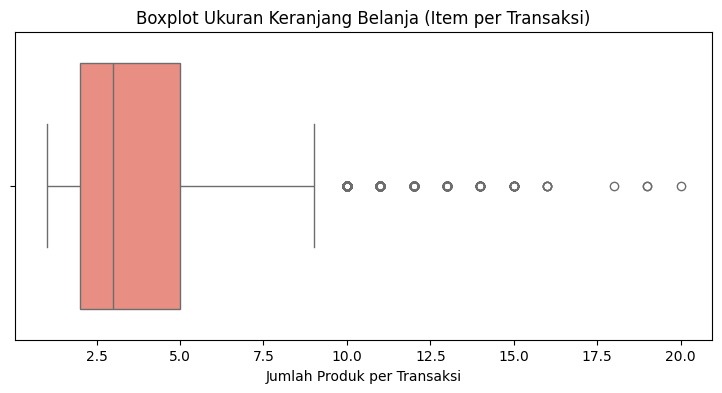

In [17]:
plt.figure(figsize=(9, 4))
sns.boxplot(x=item_per_transaksi, color='salmon')
plt.title('Boxplot Ukuran Keranjang Belanja (Item per Transaksi)')
plt.xlabel('Jumlah Produk per Transaksi')
plt.show()


### 18. Perhitungan Kuartil (Q1, Q3) dan IQR
Menghitung batas kuartil bawah (25%), kuartil atas (75%), dan rentang antarkuartil (IQR).


In [18]:
Q1 = item_per_transaksi.quantile(0.25)
Q3 = item_per_transaksi.quantile(0.75)
IQR = Q3 - Q1
print(f"Q1 (Kuartil Bawah) : {Q1}")
print(f"Q3 (Kuartil Atas)  : {Q3}")
print(f"IQR               : {IQR}")


Q1 (Kuartil Bawah) : 2.0
Q3 (Kuartil Atas)  : 5.0
IQR               : 3.0


### 19. Perhitungan Batas Atas Outlier
Menghitung ambang batas atas deteksi outlier menggunakan rumus Q3 + (1.5 * IQR).


In [19]:
batas_atas = Q3 + 1.5 * IQR
print("Batas Atas Outlier:", batas_atas)


Batas Atas Outlier: 9.5


### 20. Jumlah Transaksi Terdeteksi Outlier
Menghitung total transaksi belanja yang melampaui batas atas IQR.


In [20]:
outliers = item_per_transaksi[item_per_transaksi > batas_atas]
print("Jumlah Transaksi Outlier:", len(outliers))


Jumlah Transaksi Outlier: 395


### 21. Daftar Transaksi dengan Pembelian Terbanyak
Menampilkan 10 transaksi teratas dengan volume belanja grosir tertinggi.


In [21]:
outliers.sort_values(ascending=False).head(10).to_frame(name='Jumlah Item Belanja')


,Jumlah Item Belanja
0,20
1111,19
1120,19
1623,18
1707,16
2358,16
1604,16
2489,16
5447,15
1613,15
